In [1]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from ne_aligned_utils.plot import plot_aligned_embedding
import ot
import cne

env: CUDA_VISIBLE_DEVICES=1


In [134]:
fig_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned/figures"

# Circle and square dataset

In [26]:
# first dataset: circle with noise
n = 400
theta = np.linspace(0, 2 * np.pi, n)
x1 = np.cos(theta) + 0.1 * np.random.randn(n)
x2 = np.sin(theta) + 0.1 * np.random.randn(n)
x = np.stack([x1, x2], axis=1)


# second dataset: square with four sides and noise
n_side = n // 4 //2
x1_side1 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x2_side1 = -1 + 0.1 * np.random.randn(n_side)
x1_side2 = 1 + 0.1 * np.random.randn(n_side)
x2_side2 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x1_side3 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x2_side3 = 1 + 0.1 * np.random.randn(n_side)
x1_side4 = -1 + 0.1 * np.random.randn(n_side)
x2_side4 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x_square = np.concatenate([
    np.stack([x1_side1, x2_side1], axis=1),
    np.stack([x1_side2, x2_side2], axis=1),
    np.stack([x1_side3, x2_side3], axis=1),
    np.stack([x1_side4, x2_side4], axis=1),
], axis=0)

x_square *= 0.3


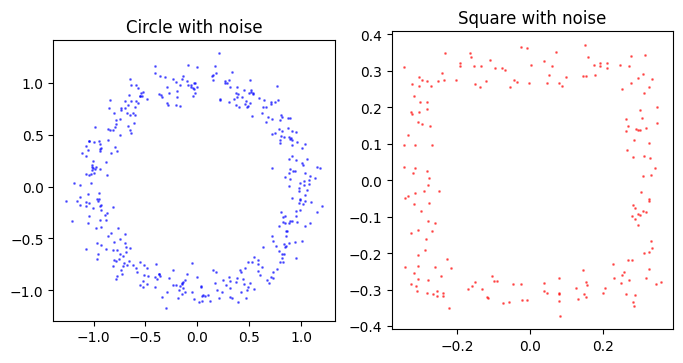

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].scatter(x[:, 0], x[:, 1], s=1.0, color="blue", alpha=0.5)
ax[0].set_title("Circle with noise")
ax[0].set_aspect("equal")
#ax[0].axis("off")
ax[1].scatter(x_square[:, 0], x_square[:, 1], s=1.0, color="red", alpha=0.5)
ax[1].set_title("Square with noise")
ax[1].set_aspect("equal")
#ax[1].axis("off")


In [28]:
# kNNs from other dataset
from sklearn.neighbors import NearestNeighbors
k = 15

nbrs_circle = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x_square)
_, indices_circle = nbrs_circle.kneighbors(x)

nbrs_square = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x)
_, indices_square = nbrs_square.kneighbors(x_square)


In [29]:
indices_circle.shape

(400, 15)

(np.float64(-1.387630548666695),
 np.float64(1.3289051443312891),
 np.float64(-1.2919403411115669),
 np.float64(1.4128460296119716))

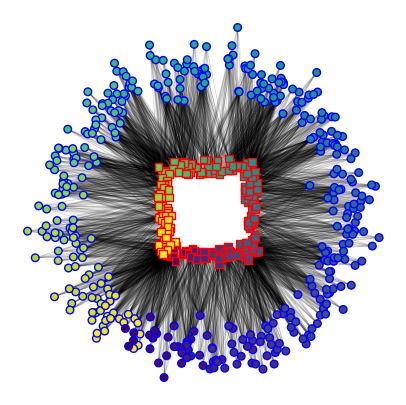

In [32]:
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(x[:, 0],
           x[:, 1],
           s=30.0,
           facecolors=plt.cm.viridis(((np.arange(len(x)) - len(x)/1.5) % len(x))/len(x)),
           edgecolors="blue",
           linewidth=1,
           marker="o",
           alpha=1,
           zorder=10)
ax.scatter(x_square[:, 0],
           x_square[:, 1],
           s=30.0,
           facecolors=plt.cm.viridis(np.linspace(0, 1, len(x_square))),
           edgecolor="red",
           linewidth=1,
           marker="s",
           alpha=1,
           zorder=10)

for i in range(0, x.shape[0], 1):
    for j in indices_circle[i]:
        ax.plot([x[i, 0], x_square[j, 0]], [x[i, 1], x_square[j, 1]], color="k", alpha=0.1, linewidth=0.5)
for i in range(0, x_square.shape[0], 1):
    for j in indices_square[i]:
        ax.plot([x_square[i, 0], x[j, 0]], [x_square[i, 1], x[j, 1]], color="k", alpha=0.1, linewidth=0.5)
ax.set_aspect("equal")
ax.axis("off")

#fig.savefig(os.path.join(fig_path, "alignment_example_data.png"), dpi=300)

In [34]:
from scipy.sparse import coo_matrix
rows = np.concatenate([np.arange(x.shape[0]).repeat(k), np.arange(x_square.shape[0]).repeat(k) + x.shape[0]])
cols = np.concatenate([indices_circle.flatten() + x.shape[0], indices_square.flatten()])

graph = coo_matrix((np.ones_like(rows), (rows, cols)), shape=(x.shape[0] + x_square.shape[0], x.shape[0] + x_square.shape[0]))


In [31]:
from ne_aligned_utils.utils import get_bipartite_graph

array([[ 90,  79,  92, ...,  73,  86,  64],
       [ 90,  79,  92, ..., 100,  82,  95],
       [ 92,  90, 100, ...,  91,  98,  82],
       ...,
       [ 50,  63,  49, ...,  69,  53,  76],
       [ 50,  63,  60, ...,  57,  76,  61],
       [ 79,  74,  75, ...,  55,  73,  68]], shape=(400, 15))

In [35]:
init = np.random.randn(len(x)+len(x_square), 2)

In [36]:
init.shape

(600, 2)

In [39]:
embedder = cne.CNE(negative_samples=5, batch_size=2**14, embd_dim=2, n_epochs=200, metric="euclidean", loss_mode="infonce", alignment=True, data_on_gpu="True", sample_pos="per_point")

In [40]:
data = np.concatenate([x, x_square], axis=0)
embd = embedder.fit_transform(data, graph=graph, init=init)

Finished epoch 0/200, loss 902.835
Finished epoch 40/200, loss 735.209
Finished epoch 80/200, loss 462.866
Finished epoch 120/200, loss 452.546
Finished epoch 160/200, loss 431.393


(np.float64(-6.225560970080803),
 np.float64(5.762036366290097),
 np.float64(-6.362296777044199),
 np.float64(6.278215288590646))

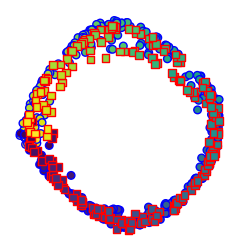

In [41]:
fig, ax = plt.subplots(figsize=(3,3))
ax.scatter(*embd[:x.shape[0]].T,
           s=30.0,
           facecolors=plt.cm.viridis(((np.arange(len(x)) - len(x)/1.5) % len(x))/len(x)),
           edgecolors="blue",
           linewidth=1,
           marker="o",
           alpha=1,
           zorder=10)
ax.scatter(*embd[x.shape[0]:].T,
           s=30.0,
           facecolors=plt.cm.viridis(np.linspace(0, 1, len(x_square))),
           edgecolor="red",
           linewidth=1,
           marker="s",
           alpha=1,
           zorder=10)
ax.set_aspect("equal")
ax.axis("off")
#fig.savefig(os.path.join(fig_path, "alignment_example_embd.png"), dpi=300)

In [26]:
# OT variant

In [56]:
cost.shape

(400, 200)

In [57]:
print(cost[:5, :5])

[[171.50150382 172.71293092 170.78196038 172.87186835 172.31662997]
 [172.32691995 173.53960466 171.60821643 173.69128313 173.1379558 ]
 [170.23548559 171.44272798 169.51815666 171.60243745 171.04866868]
 [163.84032453 165.02006467 163.14381079 165.15562237 164.62129715]
 [165.59680393 166.78297993 164.8963462  166.91986235 166.38243586]]


In [58]:
cost = ot.dist(x, x_square+ 10)
a = np.ones((x.shape[0],)) / x.shape[0]
b = np.ones((x_square.shape[0],)) / x_square.shape[0]
eps = np.median(cost)
P = ot.sinkhorn(a, b, cost, reg=eps/500)


In [60]:
eps

np.float64(200.57609058390312)

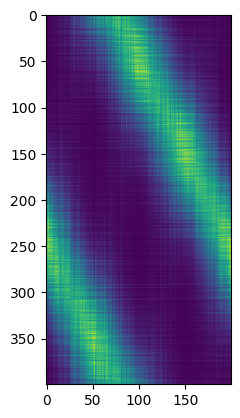

In [75]:
plt.imshow(P)

In [73]:
np.sort(P[0])
#>> have to decrease eps a lot to make it fairly sparse. Need to set quite a bit to zero. This I can do also for stronger regularization.

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

(array([   46.,   706.,  3133.,  7479., 10954., 10166.,  8741.,  8499.,
         9965., 20311.]),
 array([-205.8350183 , -185.94094793, -166.04687757, -146.1528072 ,
        -126.25873684, -106.36466647,  -86.47059611,  -66.57652574,
         -46.68245537,  -26.78838501,   -6.89431464]),
 <BarContainer object of 10 artists>)

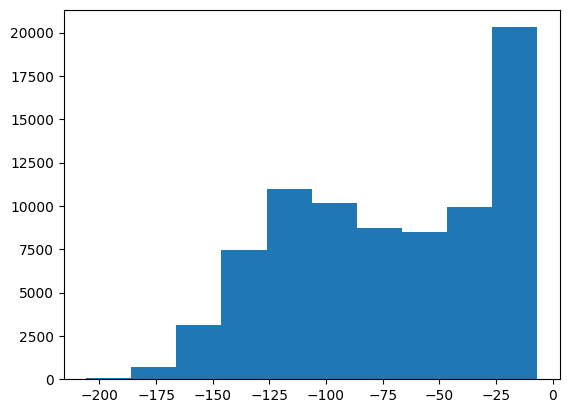

In [54]:
plt.hist(np.log(P.flatten()))

# Fig 1 data

In [48]:
import numpy as np

# Parameters
n0 = int(1e3)
n1 = int(5e3)
tol = 1e-12
maxIter = int(1e4)


seed = 0



In [166]:
from ne_aligned_utils.data import make_fig1_data

In [167]:
fig1_data = make_fig1_data(n0=n0, n1=n1, seed=seed)

In [168]:
fig1_data[0].shape

(1000, 3)

In [169]:
dist = ot.dist(fig1_data[0], fig1_data[1]) # this is already the squared Euclidean distance
eps = np.median(dist) # square of median and median of squares are the same

a = np.ones((n0,)) / n0
b = np.ones((n1,)) / n1

In [170]:
dist.shape

(1000, 5000)

In [171]:
eps

np.float64(14.744649042818404)

In [172]:
P = ot.sinkhorn(a, b, dist, reg=eps/100, numItermax=maxIter, stopThr=tol)

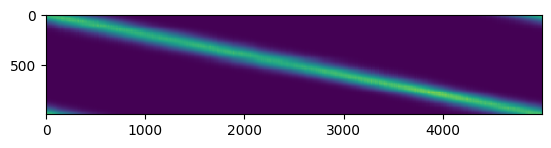

In [173]:
plt.imshow(P)

In [174]:
P.sum(0)

array([0.0002, 0.0002, 0.0002, ..., 0.0002, 0.0002, 0.0002], shape=(5000,))

In [175]:
P.max()

np.float64(2.1703828481976886e-06)

(array([   514.,   2178.,   4274.,   7086.,  11088.,  16938.,  23507.,
         32504.,  42963.,  55620.,  68957.,  81933.,  94050., 106241.,
        115902., 124373., 131202., 134059., 132774., 129306., 125326.,
        121293., 115928., 109813., 104301.,  99112.,  96796.,  93881.,
         92904.,  91202.,  90596.,  90572.,  90257.,  90951.,  91512.,
         92020.,  93947.,  95739.,  97997., 100952., 103855., 109591.,
        114565., 121668., 133014., 147263., 170003., 214028., 381201.,
        204244.]),
 array([-37.75538909, -37.26109345, -36.7667978 , -36.27250216,
        -35.77820652, -35.28391088, -34.78961524, -34.29531959,
        -33.80102395, -33.30672831, -32.81243267, -32.31813702,
        -31.82384138, -31.32954574, -30.8352501 , -30.34095446,
        -29.84665881, -29.35236317, -28.85806753, -28.36377189,
        -27.86947624, -27.3751806 , -26.88088496, -26.38658932,
        -25.89229368, -25.39799803, -24.90370239, -24.40940675,
        -23.91511111, -23.42081546, 

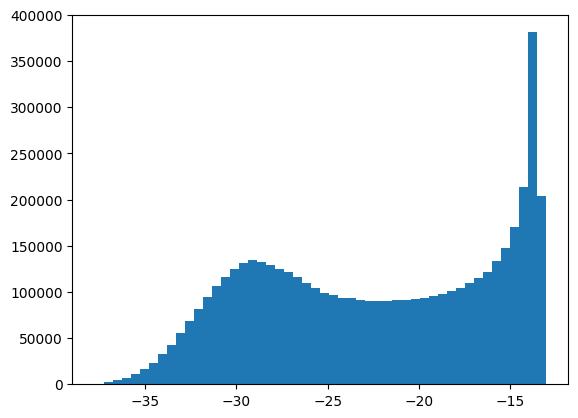

In [176]:
plt.hist(np.log(P.flatten()), bins=50)

(0.0, 0.0011000000000000014)

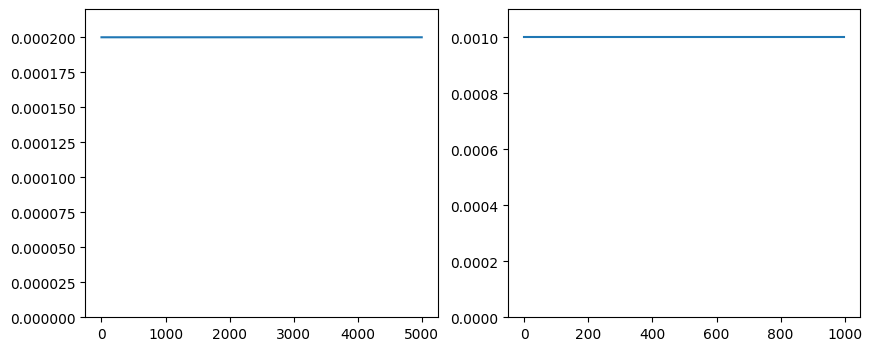

In [177]:
plan = P
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(plan.sum(0))
ax[0].set_ylim(0, 1.1*max(plan.sum(0)))

ax[1].plot(plan.sum(1))
ax[1].set_ylim(0, 1.1*max(plan.sum(1)))

In [178]:
k = 15

P_sparse = np.zeros_like(P)
for i in range(P.shape[0]):
    idx = np.argpartition(P[i], -k)[-k:]
    P_sparse[i, idx] = 1

for j in range(P.shape[1]):
    idx = np.argpartition(P[:, j], -k)[-k:]
    P_sparse[idx, j] = 1

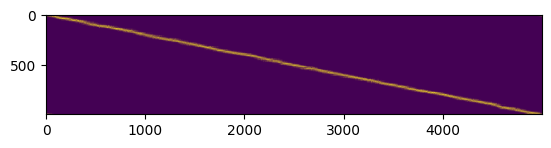

In [179]:
plt.imshow(P_sparse)

(0.0, 191.4)

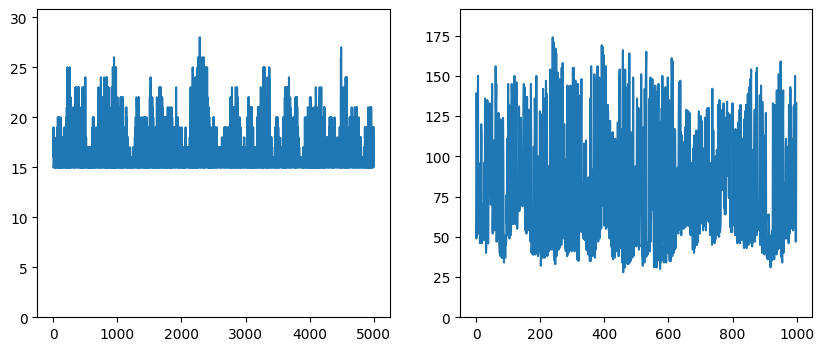

In [180]:
plan = P_sparse
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(plan.sum(0))
ax[0].set_ylim(0, 1.1*max(plan.sum(0)))

ax[1].plot(plan.sum(1))
ax[1].set_ylim(0, 1.1*max(plan.sum(1)))

In [181]:
# set only close to zero values to zero
P_half_sparse = P * P_sparse

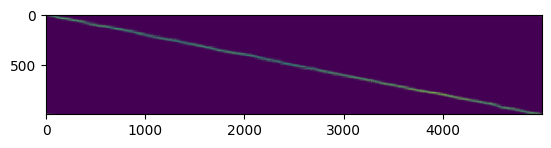

In [182]:
plt.imshow(P_half_sparse)

(0.0, 0.0002963550741346878)

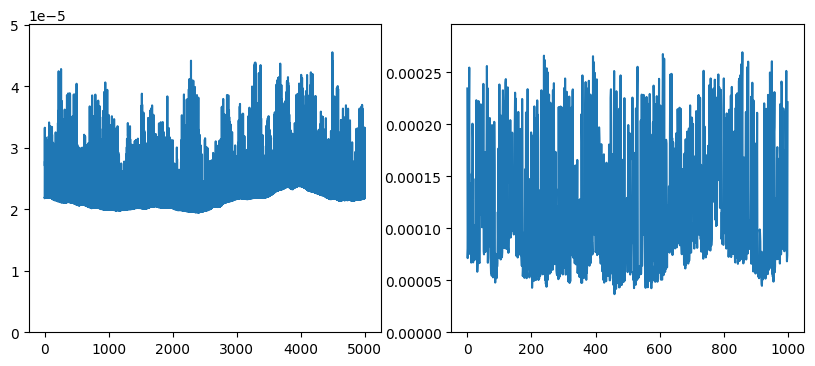

In [183]:
plan = P_half_sparse
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(plan.sum(0))
ax[0].set_ylim(0, 1.1*max(plan.sum(0)))

ax[1].plot(plan.sum(1))
ax[1].set_ylim(0, 1.1*max(plan.sum(1)))

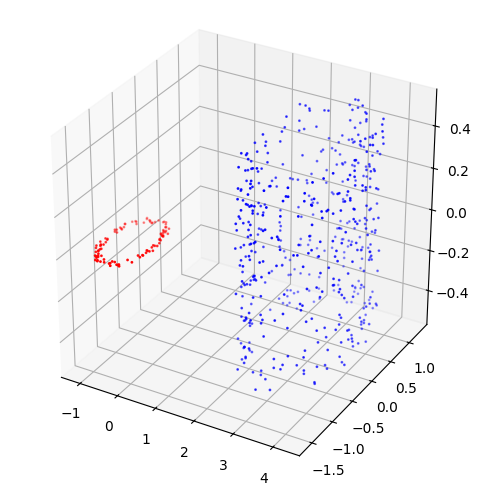

In [736]:
# plot in 3d
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*fig1_data[0].T, c='r', s=1)
ax.scatter(*fig1_data[1].T, c='b', s=1)
ax.set_box_aspect([1,1,1])  # Equal aspect ratio

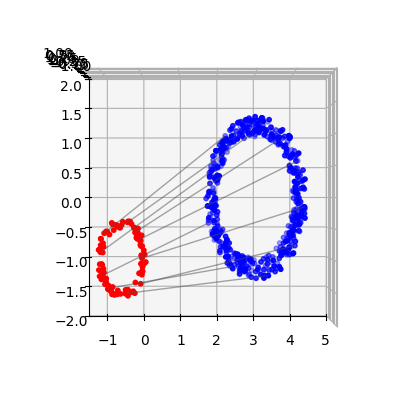

In [737]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection
%matplotlib inline
# Indices of max partner per row / column
idx_row = P.argmax(axis=1)[::10]       # for each i in X1 -> best j in X2
idx_col = P.argmax(axis=0)[::10]        # for each j in X2 -> best i in X1

# Build line segments
segs_row = np.stack([fig1_data[0][::10]  ,fig1_data[1][idx_row]], axis=1)           # (n1, 2, 3)
segs_col = np.stack([fig1_data[1][::10]  , fig1_data[0][idx_col]], axis=1)           # (n1, 2, 3)

# Plot
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(*fig1_data[0].T, s=10, c='r', zorder=10)  # source cloud
ax.scatter(*fig1_data[1].T, s=10, c='b', zorder=10)  # target cloud

# Add semi-transparent line collections
lc1 = Line3DCollection(segs_row, colors=(0.3, 0.3, 0.3, 0.5), linewidths=1.0)
#lc2 = Line3DCollection(segs_col, colors=(0.3, 0.3, 0.3, 0.5), linewidths=1.0)
ax.add_collection3d(lc1)
#ax.add_collection3d(lc2)

# Match MATLAB view/limits and hide axes
ax.set_xlim(-1.5, 5)
ax.set_ylim(-2, 2)
ax.set_zlim(-1, 1)
#ax.set_box_aspect((6.5, 4, 2))   # keep proportions reasonable
#ax.set_axis_off()
ax.view_init(elev=90, azim=-90)

In [184]:
data =  np.concatenate(fig1_data, axis=0)
init = np.random.randn(fig1_data[0].shape[0] + fig1_data[1].shape[0], 2) * 2

In [186]:
B_sparse = get_bipartite_graph(P_half_sparse)

In [70]:
embedder = cne.CNE(negative_samples=5, batch_size=2**14, embd_dim=2, n_epochs=200, metric="euclidean", loss_mode="infonce", alignment=True, data_on_gpu=True, sample_pos="per_point")
embd = embedder.fit_transform(data, graph=B_sparse, init=init)

Finished epoch 0/200, loss 13988.779
Finished epoch 40/200, loss 8399.357
Finished epoch 80/200, loss 5740.766
Finished epoch 120/200, loss 5174.710
Finished epoch 160/200, loss 5067.173


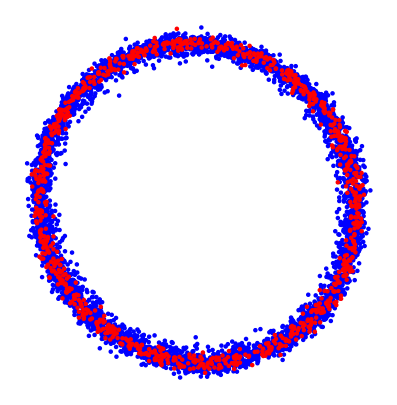

In [71]:
#colors =  ["r"]*n0 + [cmap(fig1_data[1][i, 2] + 0.5) for i in range(n1)]
colors =  ["r"]*n0 + ["b"]*n1
seed = 2
fig = plot_aligned_embedding(embd[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             shuffle=False,
                             seed=seed)

In [664]:
from sklearn.neighbors import NearestNeighbors




In [665]:
fig1_data_clean0 = fig1_data[0][:, :2] + np.array([0.5, 1])
fig1_data_clean1 = fig1_data[1][:, :2] + np.array([-3, 0])
fig1_data_clean = np.concatenate([fig1_data_clean0, fig1_data_clean1], axis=0)

In [666]:
concordance = compute_concordance(fig1_data_clean, embd, k=50)

In [667]:
concordance

np.float64(0.38415262142245077)

In [668]:
U, S, V  = np.linalg.svd(P, full_matrices=False)

In [669]:
U.shape

(1000, 1000)

In [670]:
V.shape

(1000, 5000)

In [671]:
embd_le = np.concatenate([U[:, 1:3]*np.sqrt(n0), V.T[:, 1:3]*np.sqrt(n1)], axis=0)

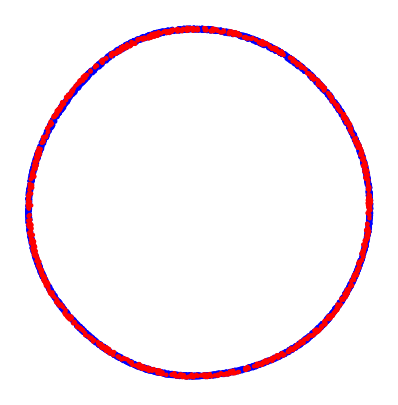

In [672]:
colors =  ["r"]*n0 + ["b"]*n1
seed = 2
fig = plot_aligned_embedding(embd_le[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             #fig_name=os.path.join(fig_path, "alignment_example_fig1_dense.png"),
                             shuffle=False,
                             seed=seed)

In [673]:
concordance_le = compute_concordance(fig1_data_clean, embd_le, k=50)

In [674]:
concordance_le

np.float64(0.24694897633101554)

# within data set repulsion

In [708]:
data =  np.concatenate(fig1_data, axis=0)
init = np.random.randn(fig1_data[0].shape[0] + fig1_data[1].shape[0], 2) * 2

In [709]:
B_sparse = get_bipartite_graph(P_sparse)

In [746]:
embedder = cne.CNE(negative_samples=5, batch_size=2**14, embd_dim=2, n_epochs=100, metric="euclidean", loss_mode="nce", alignment=True, data_on_gpu=True, sample_pos=None)
embd = embedder.fit_transform(data, graph=B_sparse, init=init)

Finished epoch 0/100, loss 124592.355
Finished epoch 20/100, loss 125787.991
Finished epoch 40/100, loss 115380.948
Finished epoch 60/100, loss 101391.751
Finished epoch 80/100, loss 83620.091


(np.float64(-1.753105152411669),
 np.float64(1.4636884131793113),
 np.float64(-2.355443085508861),
 np.float64(2.460665376670696))

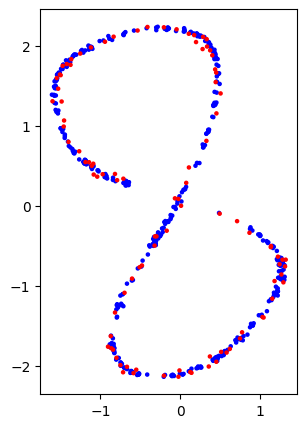

In [747]:
colors =  ["r"]*n0 + ["b"]*n1
seed = 2
fig = plot_aligned_embedding(embd[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             #fig_name=os.path.join(fig_path, "alignment_example_fig1_dense.png"),
                             shuffle=False,
                             seed=seed)
ax = fig.get_axes()[0]
ax.axis("on")

In [688]:
embedder.cne.alignment

True

In [680]:
concordance = compute_concordance(fig1_data_clean, embd, k=50)

In [681]:
print(concordance)

0.3822632123599809


In [729]:
from cne.cne import make_neighbor_indices

alignment = True
negative_samples = 5
batch_size = 10
neigh_idx = make_neighbor_indices(batch_size, negative_samples, alignment=alignment, device="cpu")

In [730]:
print(neigh_idx % (2*batch_size))

tensor([[10, 15, 13, 11, 13, 18],
        [11, 16, 16, 15, 18, 18],
        [12, 12, 17, 15, 12, 14],
        [13, 16, 17, 13, 11, 16],
        [14, 16, 11, 11, 17, 14],
        [15, 18, 11, 11, 17, 17],
        [16, 11, 17, 17, 17, 15],
        [17, 14, 15, 12, 13, 14],
        [18, 16, 14, 13, 13, 10],
        [19, 11, 13, 12, 17, 17],
        [ 0,  3,  4,  0,  7,  8],
        [ 1,  1,  8,  5,  2,  2],
        [ 2,  1,  8,  5,  2,  8],
        [ 3,  3,  3,  6,  4,  4],
        [ 4,  3,  1,  2,  3,  6],
        [ 5,  3,  4,  5,  7,  1],
        [ 6,  0,  0,  6,  0,  6],
        [ 7,  8,  2,  5,  2,  3],
        [ 8,  8,  5,  0,  3,  8],
        [ 9,  7,  2,  4,  3,  5]])


In [14]:
n=5

r=3

x= np.tile(np.arange(n).reshape(-1, 1), reps=(1, r))
print(x)

[[0 0 0]
 [1 1 1]
 [2 2 2]
 [3 3 3]
 [4 4 4]]


In [18]:
ind_k = np.tile(np.arange(r), reps=(n, 1))
ind_n = np.tile(np.arange(n).reshape(-1, 1), reps=(1, r))

mask1 = (1 <= ind_k) & (ind_n <= n//3)

In [19]:
print(mask1)

[[False  True  True]
 [False  True  True]
 [False False False]
 [False False False]
 [False False False]]


In [107]:
from ne_aligned_utils.data import make_joint_gmm

In [108]:
c0, c1, cluster0, cluster1 = make_joint_gmm(n0=600, n1=600, p=1000, q=6, seed=0, clean=True)
d0, d1 = make_joint_gmm(n0=600, n1=600, p=1000, q=6, seed=0)

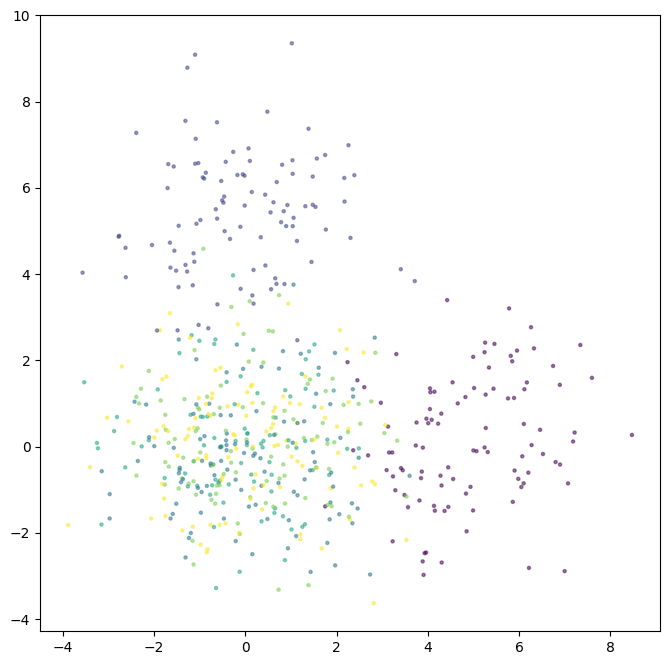

In [110]:
5fig, ax = plt.subplots(figsize=(8, 8))
#ax.scatter(d0[:, 0], d0[:, 1], c=cluster0, s=5, alpha=0.5)
ax.scatter(d1[:, 0], d1[:, 1], c=cluster1, s=5, alpha=0.5)

In [93]:
from openTSNE import TSNE

In [111]:
tsne_embedder = TSNE(n_components=2)
tsne0 = tsne_embedder.fit(c0)

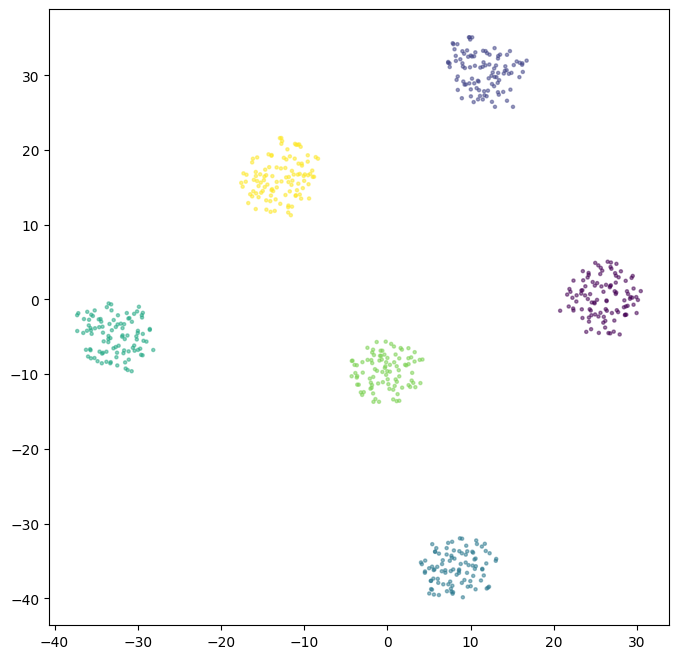

In [114]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(tsne0[:, 0], tsne0[:, 1], c=cluster0, s=5, alpha=0.5)

In [112]:
tsne_embedder = TSNE(n_components=2)
tsne1 = tsne_embedder.fit(c1)

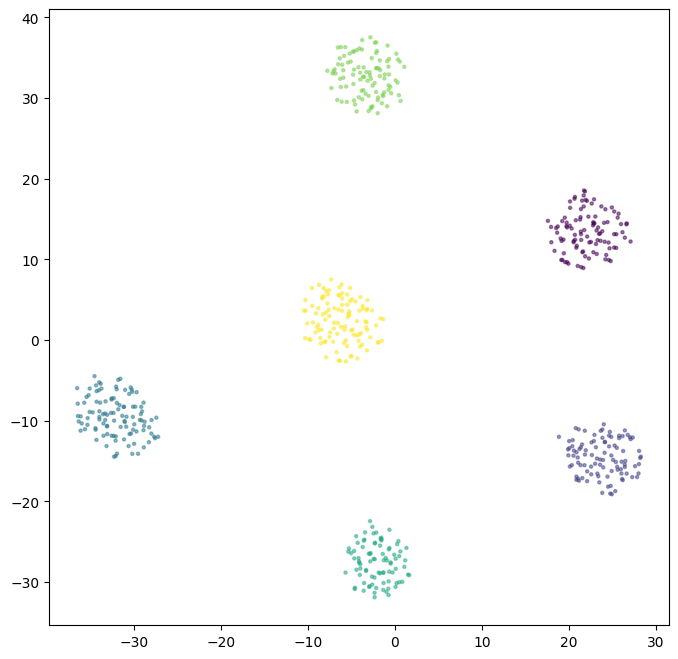

In [113]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(tsne1[:, 0], tsne1[:, 1], c=cluster1, s=5, alpha=0.5)

In [121]:
from ne_aligned_utils.metrics import compute_kmeans_rand

In [122]:
ari = compute_kmeans_rand(embd=tsne1, gt=cluster1)
print(ari)

1.0


In [115]:
tsne_embedder = TSNE(n_components=2)
tsnej = tsne_embedder.fit(np.concatenate([d0, d1], axis=0))

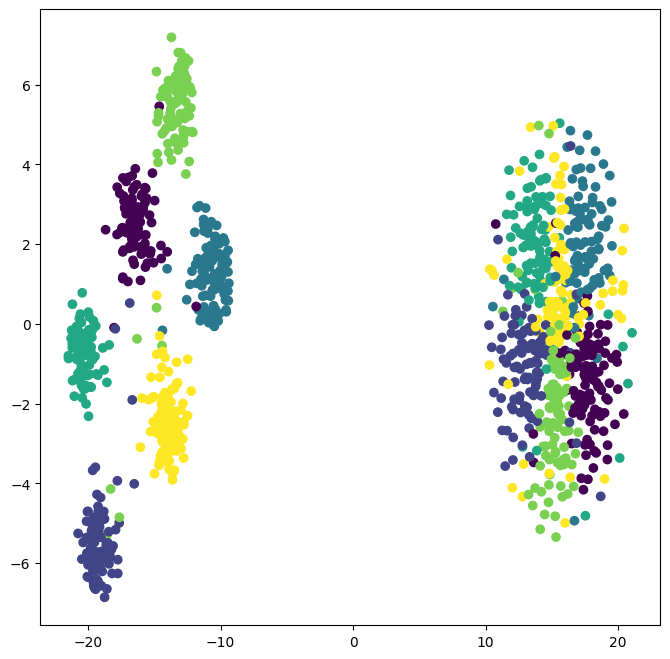

In [116]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(*tsnej.T, c=np.concatenate([cluster0, cluster1], axis=0))

In [117]:
np.linalg.svd(np.eye(2), full_matrices=False)

SVDResult(U=array([[1., 0.],
       [0., 1.]]), S=array([1., 1.]), Vh=array([[1., 0.],
       [0., 1.]]))

In [124]:
file = "gmm_theta_1.0_seed_0_epstimes_1_sparsify_None_dim_6_EOT_t_0.npz"
res_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm"
a = np.load(os.path.join(res_path, file))
embd = a["embd"]

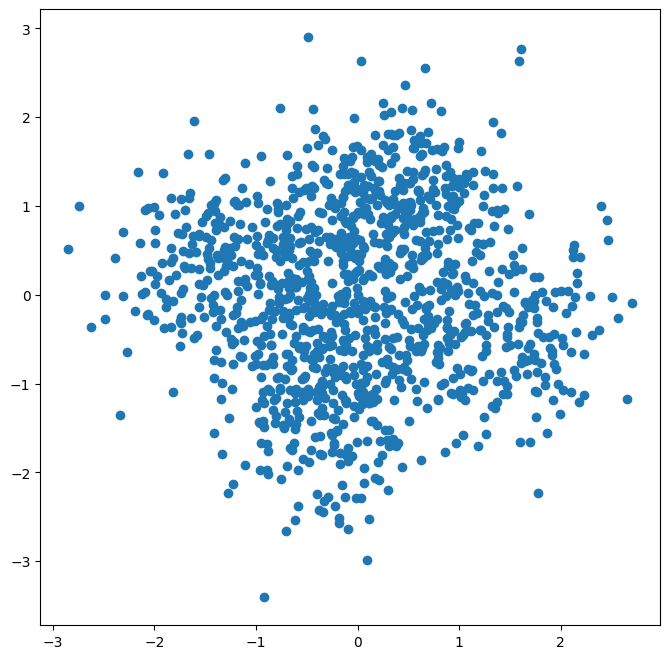

In [144]:
metrics_file = "gmm_theta_1.0_epstimes_100_sparsify_None_dim_2_EOT_t_1_metrics.npz"
metrics = np.load(os.path.join(res_path, metrics_file))
concordance = metrics["concordance"]
rand = metrics["rand"]

In [145]:
print(concordance)
print(rand)

[0.13896042 0.12756422 0.13674493 0.13306115 0.12461205]
[0.4870174  0.37122928 0.40599698 0.40037006 0.37542309]


In [142]:
file = "gmm_theta_1.0_seed_0_epstimes_1_sparsify_None_dim_2_EOT_t_0.npz"
res_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm"
a = np.load(os.path.join(res_path, file))
embd = a["embd"]

In [149]:
metrics_file = "gmm_theta_3.0_epstimes_100_sparsify_topk_dim_6_init_random_scale_1_bs_16384_m_5_epochs_200_loss_infonce_align_True_sample_pos_None_metrics.npz"
metrics = np.load(os.path.join(res_path, metrics_file))
concordance = metrics["concordance"]
rand = metrics["rand"]
print(concordance)
print(rand)

[0.26122945 0.26902981 0.2765153  0.26459185 0.27583346]
[0.99607952 0.99602798 0.98444296 0.99188067 0.99201213]


In [155]:
filename = "gmm_theta_1_seed_0_epstimes_1_sparsify_topk_dim_2_init_random_scale_1_bs_16384_m_500_epochs_200_loss_infonce_align_False_sample_pos_None.npz"
dir_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned/gmm/"

In [156]:
a = np.load(os.path.join(dir_path, filename))

In [157]:
embd = a["embd"]

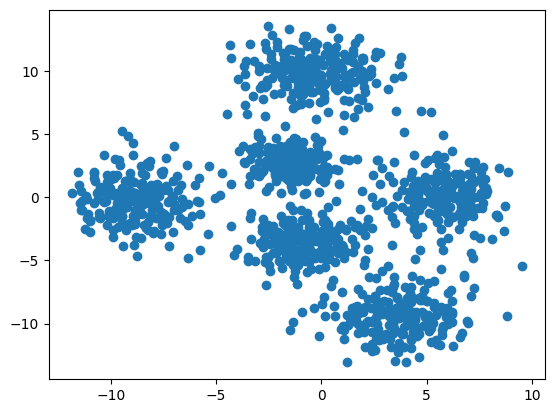

In [158]:
fig, ax = plt.subplots()

ax.scatter(*embd.T)

In [161]:

seeds = [0, 1, 2, 3 ,4]
dataset = "gmm"
thetas = [1]

tol = 1e-12
maxIter = int(1e4)

eps_times_list = [1, 10, 100]
sparsify = "topk" # None # "topk" # None
embd_dim = 2

alignment = False
sample_pos = None #"per_point" #None #


init_str = "random"  # "pca" or "random"
init_scale = 1
batch_size = 2**14
negative_samples = 500
n_epochs = 200
loss_mode = "infonce"



concordances_topk = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
rand_topk = np.zeros((len(thetas), len(eps_times_list), len(seeds)))
for i, theta in enumerate(thetas):
    for j, eps_times in enumerate(eps_times_list):
        metrics_path = os.path.join(res_path,
                                    f"{dataset}_theta_{theta}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                    f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                    f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
        metrics = np.load(metrics_path)
        concordances_topk[i, j] = metrics["concordance"]
        rand_topk[i, j] = metrics["rand"]


In [163]:
print(concordances_topk.mean(-1))

[[0.16795405 0.1662262  0.16585228]]


In [164]:
# opentsne variant

In [165]:
from openTSNE.affinity import Affinities
from openTSNE import TSNE

In [194]:
init /= (init[:, 0].std() * 10000)

In [195]:
init.std()

np.float64(9.827151034989668e-05)

In [208]:
B_sparse = get_bipartite_graph(P_sparse)

In [209]:
B_sparse / B_sparse.sum()

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 160084 stored elements and shape (6000, 6000)>

In [210]:
affinities_tSNE = Affinities()
affinities_tSNE.P = B_sparse/B_sparse.sum()

In [211]:
tsne_embedder = TSNE(n_components=2, verbose=True)
embd = tsne_embedder.fit(initialization=init, affinities=affinities_tSNE)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 250 iterations...
Iteration   50, KL divergence 5.3913, 50 iterations in 14.4467 sec
Iteration  100, KL divergence 3.6900, 50 iterations in 7.7373 sec
Iteration  150, KL divergence 3.5910, 50 iterations in 6.7531 sec
Iteration  200, KL divergence 3.4896, 50 iterations in 6.3054 sec
Iteration  250, KL divergence 3.4373, 50 iterations in 5.8385 sec
   --> Time elapsed: 41.08 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 500 iterations...
Iteration   50, KL divergence 2.2704, 50 iterations in 6.8970 sec
Iteration  100, KL divergence 2.1706, 50 iterations in 7.0689 sec
Iteration  150, KL divergence 2.1460, 50 iterations in 7.1561 sec
Iteration  200, KL divergence 2.1306, 50 iterations in 7.2532 sec


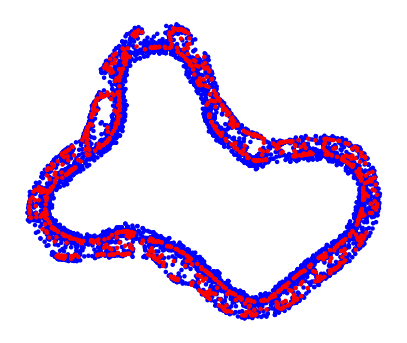

In [212]:
colors =  ["r"]*n0 + ["b"]*n1
fig = plot_aligned_embedding(embd[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             #fig_name=os.path.join(fig_path, "alignment_example_fig1_dense.png"),
                             shuffle=False,
                             seed=seed)
#ax = fig.get_axes()[0]
#ax.axis("on")

In [213]:
clean0, clean1 = make_fig1_data(seed=seed, clean=True)

clean = np.concatenate((clean0, clean1))

In [214]:
from ne_aligned_utils.metrics import compute_concordance

In [215]:
compute_concordance(embd, clean)

np.float64(0.3783556161503845)

In [216]:
graph.shape

(600, 600)

In [217]:
B_sparse = get_bipartite_graph(P_sparse)


In [218]:
B_sparse.shape

(6000, 6000)

In [219]:
B_sparse.sum(1)

matrix([[139.],
        [ 49.],
        [ 55.],
        ...,
        [ 15.],
        [ 15.],
        [ 19.]], shape=(6000, 1))

In [220]:
graph = B_sparse.copy()

graph.sum_duplicates()
graph /= graph.sum(1)
graph = (graph.T + graph) / (2*graph.shape[0])  # make symmetric
assert np.allclose(graph.sum(), 1)

In [224]:
graph.sum(0)

matrix([[7.80234184e-04, 3.55555556e-04, 3.71992123e-04, ...,
         1.03890749e-04, 1.03890749e-04, 9.89099513e-05]], shape=(1, 6000))

In [225]:
from ne_aligned_utils.metrics import compute_cross_concordance

In [226]:
compute_concordance(embd, clean)

np.float64(0.3783556161503845)

In [227]:
clean0, clean1 = make_fig1_data(seed=seed, clean=True)

embd0, embd1 = embd[:n0], embd[n0:]

In [239]:
compute_cross_concordance(clean0, clean1, embd0, embd1)

np.float64(0.37016809070987355)

In [235]:
dir_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned/fig1/"
filename = f"fig1_seed_{seed}_epstimes_1_sparsify_None_dim_2_EOT_t_0.npz"
a = np.load(os.path.join(dir_path, filename))
eot_embd = a["embd"]

In [236]:
compute_concordance(clean, eot_embd)

np.float64(0.6324939640704095)

In [238]:
compute_cross_concordance(clean0, clean1, eot_embd[:n0], eot_embd[n0:])

np.float64(0.3385307326302495)

In [ ]:
## figures for talk

In [3]:
from sklearn.neighbors import NearestNeighbors


In [153]:
h_blue_255 = (0, 152,205) # np.array([[0, 152,205]])

h_blue = tuple(v / 255 for v in h_blue_255)
h_pink_255 = (224, 16,149) # np.array([[224, 16,149]])

h_pink = tuple(v / 255 for v in h_pink_255)


In [30]:
n = 200
seed = 0
np.random.seed(seed)
# square

# second dataset: square with four sides and noise
n_side = n // 4 //2
x1_side1 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x2_side1 = -1 + 0.1 * np.random.randn(n_side)
x1_side2 = 1 + 0.1 * np.random.randn(n_side)
x2_side2 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x1_side3 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x2_side3 = 1 + 0.1 * np.random.randn(n_side)
x1_side4 = -1 + 0.1 * np.random.randn(n_side)
x2_side4 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x_square = np.concatenate([
    np.stack([x1_side1, x2_side1], axis=1),
    np.stack([x1_side2, x2_side2], axis=1),
    np.stack([x1_side3, x2_side3], axis=1),
    np.stack([x1_side4, x2_side4], axis=1),
], axis=0)

angle = np.pi/4
x_square = x_square @ np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
x_square = np.roll(x_square, shift= n//4, axis=0 )

x_square *= 0.5

# circle
theta = np.linspace(0, 2 * np.pi, n)
x1 = np.cos(theta) + 0.1 * np.random.randn(n)
x2 = np.sin(theta) + 0.1 * np.random.randn(n)
x_circ = np.stack([x1, x2], axis=1)

x_circ += np.array([3,0])

x = np.concatenate([x_square, x_circ], axis=0)

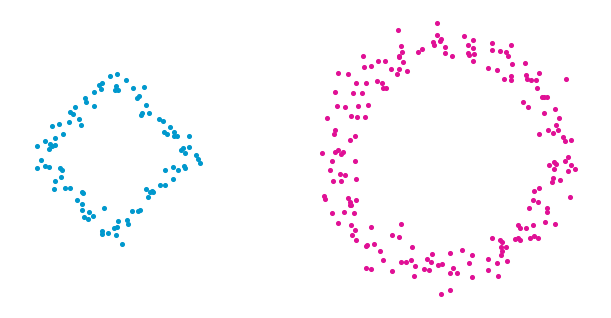

In [154]:
fig,ax = plt.subplots(constrained_layout=True, figsize=(6,4))

ax.scatter(*x_square.T, s=7, color=h_blue)
ax.scatter(*x_circ.T, s=7  , color=h_pink)
ax.set_aspect("equal")
ax.axis("off")
fig.savefig(os.path.join(fig_path, "raw_data.png"), dpi=500)

In [32]:
k = 6

nbrs_all = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x)
_, indices = nbrs_all.kneighbors(x)

In [33]:
print(indices[:10, :])

[[ 0 97 99 95 96 98]
 [ 1  5 98  3  2  4]
 [ 2  3  4  1  8  5]
 [ 3  1 98  5  2 99]
 [ 4  8  6  9 10  2]
 [ 5  1 98  3  4  8]
 [ 6  8  4 10  9  7]
 [ 7  9 10  6  8 11]
 [ 8  4  6  9 10  7]
 [ 9  7  6 10  8  4]]


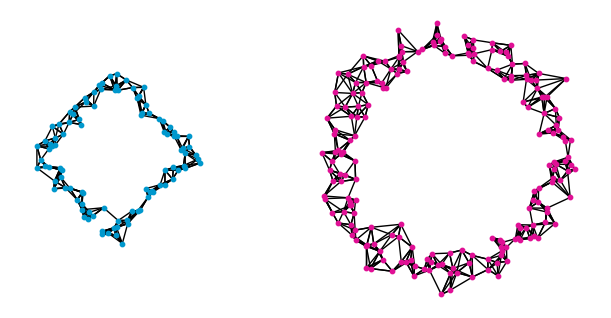

In [155]:
fig,ax = plt.subplots(constrained_layout=True, figsize=(6,4))

ax.scatter(*x_square.T,zorder=10,  s=10, color=h_blue)
ax.scatter(*x_circ.T,  zorder=10, s=10, color=h_pink)
ax.set_aspect("equal")
ax.axis("off")
for i in range(0, x.shape[0], 1):
    for j in indices[i][1:]:
        ax.plot([x[i, 0], x[j, 0]], [x[i, 1], x[j, 1]], color="k", alpha=1, linewidth=1)
fig.savefig(os.path.join(fig_path, "knn.png"), dpi=500)


In [35]:
k = 5

nbrs_circle = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x_square)
_, indices_circle = nbrs_circle.kneighbors(x_circ)

nbrs_square = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x_circ)
_, indices_square = nbrs_square.kneighbors(x_square)

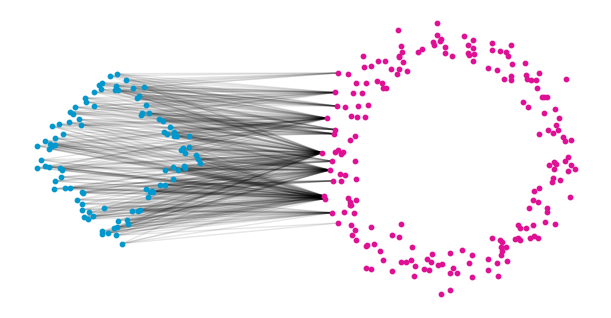

In [156]:
fig,ax = plt.subplots(constrained_layout=True, figsize=(6,4))

ax.scatter(*x_square.T,zorder=10, s=10, color=h_blue)
ax.scatter(*x_circ.T,  zorder=10, s=10, color=h_pink)
ax.set_aspect("equal")
ax.axis("off")
#for i in range(0, x_circ.shape[0], 1):
#    for j in indices_circle[i]:
#        ax.plot([x_circ[i, 0], x_square[j, 0]], [x_circ[i, 1], x_square[j, 1]], color="k", alpha=0.01, linewidth=0.5)
for i in range(0, x_square.shape[0], 1):
    for j in indices_square[i]:
        ax.plot([x_square[i, 0], x_circ[j, 0]], [x_square[i, 1], x_circ[j, 1]], color="k", alpha=0.1, linewidth=1)

fig.savefig(os.path.join(fig_path, "cross1.png"), dpi=500)


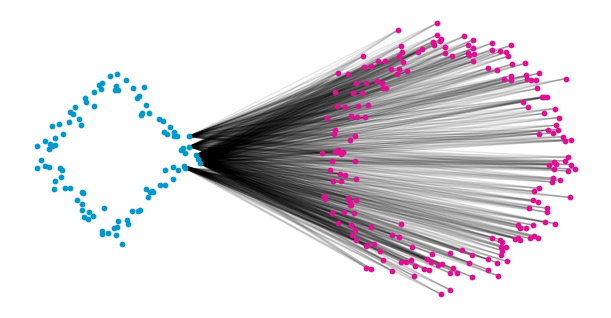

In [157]:
fig,ax = plt.subplots(constrained_layout=True, figsize=(6,4))

ax.scatter(*x_square.T,zorder=10, s=10, color=h_blue)
ax.scatter(*x_circ.T,  zorder=10, s=10, color=h_pink)
ax.set_aspect("equal")
ax.axis("off")
for i in range(0, x_circ.shape[0], 1):
    for j in indices_circle[i]:
        ax.plot([x_circ[i, 0], x_square[j, 0]], [x_circ[i, 1], x_square[j, 1]], color="k", alpha=0.1, linewidth=1)
#for i in range(0, x_square.shape[0], 1):
#    for j in indices_square[i]:
#        ax.plot([x_square[i, 0], x_circ[j, 0]], [x_square[i, 1], x_circ[j, 1]], color="k", alpha=0.1, linewidth=0.5)
fig.savefig(os.path.join(fig_path, "cross2.png"), dpi=500)

In [38]:
# Parameters
n0 = int(n/2)
n1 = int(n)
tol = 1e-12
maxIter = int(1e4)


seed = 0

dist = ot.dist(x_square, x_circ) # this is already the squared Euclidean distance
eps = np.median(dist) # square of median and median of squares are the same

a = np.ones((n0,)) / n0
b = np.ones((n1,)) / n1

In [39]:
P = ot.sinkhorn(a, b, dist, reg=eps/100, numItermax=maxIter, stopThr=tol)

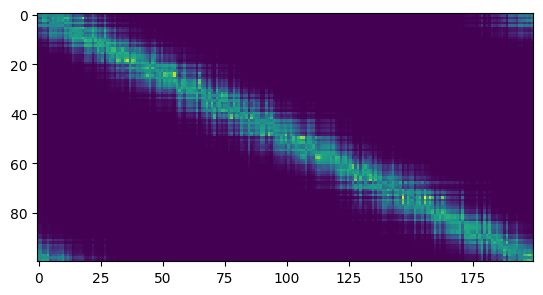

In [68]:
plt.imshow(P, vmin=0, interpolation="none")

In [62]:
from ne_aligned_utils.utils import sparsify_plan

In [91]:
P_sparse = sparsify_plan(P, mode="topk", k=5)

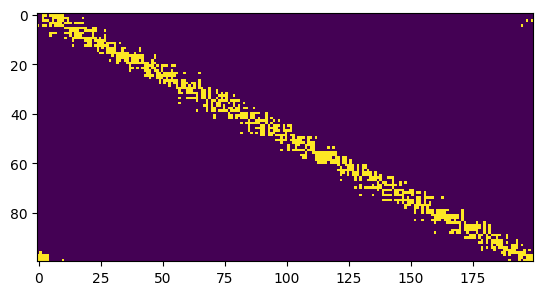

In [92]:
plt.imshow(P_sparse, interpolation="none")

In [93]:
idx_row[::10,:]

array([[100,  93, 106, 107,  78],
       [134, 107, 106, 112, 128],
       [147, 156, 134, 128, 130],
       [147, 156, 163, 158, 159],
       [188, 198, 197, 189, 196],
       [ 18, 198,   2, 197, 188],
       [ 18,  19,   2,  36,  11],
       [ 18,  55,  36,  38,  44],
       [ 55,  65,  51,  74,  44],
       [ 78,  86,  71,  74,  93]])

In [94]:
P.shape

(100, 200)

In [95]:
idx_col = np.argpartition(P, kth=5, axis=0)[:5]
print(idx_col.shape)

(5, 200)


In [96]:
np.argwhere(P_sparse[i])[0]

array([0])

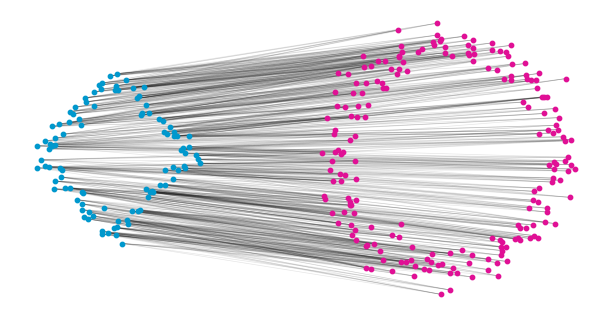

In [158]:
fig,ax = plt.subplots(constrained_layout=True, figsize=(6,4))

ax.scatter(*x_square.T,zorder=10, s=10, color=h_blue)
ax.scatter(*x_circ.T,  zorder=10, s=10, color=h_pink)
ax.set_aspect("equal")
ax.axis("off")
for i in range(0, x_square.shape[0], 1):
    for j in np.argwhere(P_sparse[i]):
        j = j[0]
        ax.plot([x_square[i, 0], x_circ[j, 0]], [x_square[i, 1], x_circ[j, 1]], color="k", alpha=0.1, linewidth=0.5)
fig.savefig(os.path.join(fig_path, "ot.png"), dpi=500)


In [100]:
U, S, V = np.linalg.svd(P, full_matrices=False)

In [101]:
t = 0.5
eot_half_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)

In [103]:
P_diag = eot_half_embd @ eot_half_embd.T / (np.sqrt(n0 * n1))


In [104]:
k = 5

P_diag_sparse = np.zeros_like(P_diag)

P_diag_sparse[:n0, :n0][np.arange(n0,dtype=int)[:, None], P_diag[:n0, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse[:n0, n0:][np.arange(n0,dtype=int)[:, None], P_diag[:n0, n0:].argsort(axis=1)[:, -int(k*n1/n0):]] = 1

P_diag_sparse[n0:, :n0][np.arange(n1,dtype=int)[:, None], P_diag[n0:, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse[n0:, n0:][np.arange(n1,dtype=int)[:, None], P_diag[n0:, n0:].argsort(axis=1)[:, -int(k*n1/n0):]] = 1

In [105]:
P_diag_sparse_sym = np.maximum(P_diag_sparse, P_diag_sparse.T)


In [106]:
import scipy.sparse as sp

In [113]:
from openTSNE import TSNE
from openTSNE.affinity import Affinities


In [115]:
n_epochs = 200
embd_dim = 2

graph_diag_sparse_sym = sp.csr_matrix(P_diag_sparse_sym / P_diag_sparse_sym.sum())
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_diag_sparse_sym.tocsr()

embd_diag_sparse_sym = embedder.fit(affinities=affinities)

Attempting to use `pca` initalization, but no `X` matrix specified! Using `spectral` initilization instead, which doesn't need access to the data matrix


--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Calculating spectral initialization...
   --> Time elapsed: 0.32 seconds
===> Running optimization with exaggeration=12.00, lr=25.00 for 66 iterations...
Iteration   50, KL divergence 1.3018, 50 iterations in 0.1588 sec
   --> Time elapsed: 0.21 seconds
===> Running optimization with exaggeration=1.00, lr=300.00 for 134 iterations...
Iteration   50, KL divergence 0.4144, 50 iterations in 0.1473 sec
Iteration  100, KL divergence 0.3928, 50 iterations in 0.1521 sec
   --> Time elapsed: 0.40 seconds


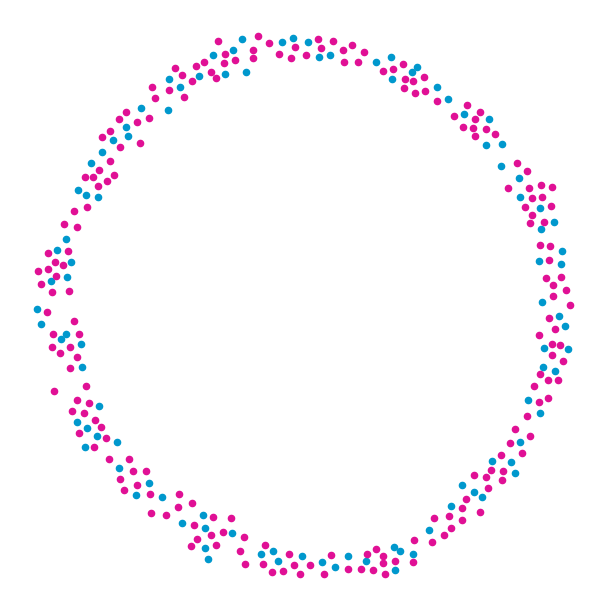

In [159]:
fig, ax  = plt.subplots(figsize=(6,6), constrained_layout=True)
ax.scatter(*embd_diag_sparse_sym[:n0].T, s=20, color=h_blue)
ax.scatter(*embd_diag_sparse_sym[n0:].T, s=20, color=h_pink)
ax.set_aspect("equal")
ax.axis("off")
fig.savefig(os.path.join(fig_path, "OT_tSNE.png"), dpi=500)


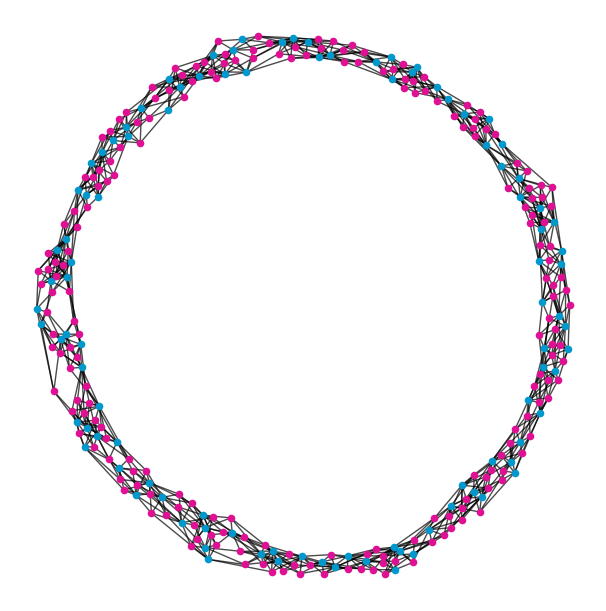

In [160]:
fig, ax  = plt.subplots(figsize=(6,6), constrained_layout=True)
ax.scatter(*embd_diag_sparse_sym[:n0].T, s=20, zorder=10, color=h_blue)
ax.scatter(*embd_diag_sparse_sym[n0:].T, s=20, zorder=10, color=h_pink)
ax.set_aspect("equal")
ax.axis("off")

for i in range(0, x_square.shape[0], 1):
    for j in np.argwhere(P_sparse[i]):
        j = j[0]
        ax.plot([embd_diag_sparse_sym[i, 0],
                 embd_diag_sparse_sym[j+n0, 0]],
                [embd_diag_sparse_sym[i, 1],
                 embd_diag_sparse_sym[j+n0, 1]], color="k", alpha=0.7, linewidth=1)
fig.savefig(os.path.join(fig_path, "OT_tSNE_graph.png"), dpi=500)



In [127]:
np.sqrt((embd_diag_sparse_sym**2).sum(-1)).mean()

TSNEEmbedding(16.96551082)